# Customer Churn Report
## Who is leaving, why it happens, and what we should do about it

*Prepared for: the management team · September 2026 · Data Science*

**How to read this notebook.** It alternates between grey code boxes (the mechanical work — reproducible by pressing *Run All*) and plain-English paragraphs. If you do not read code, simply skip every grey box: each one is followed by a graph and a "**What this means**" paragraph that states exactly what to take away and which decision it supports.

## 1. The business question

Every customer who cancels takes their monthly bill with them — forever. This report answers three questions in order:

1. **How many customers are we losing, and who are they?** (Section 3)
2. **Can we see who is likely to leave next, before they do?** (Section 4)
3. **What should we do about it, and what is it worth?** (Sections 5 and 6)

Every graph ends with the decision it informs. No graph is included for decoration.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.edgecolor"] = "#cccccc"

BLUE, RED = "#4C72B0", "#D1495B"
TITLE = dict(fontsize=13, fontweight="bold", loc="left", pad=12)

## 2. The data we used

The analysis uses one row per customer — **2,000 customers** in total — exported from the billing and CRM systems and shipped alongside this notebook as `customer_data.csv`, so every number here can be reproduced exactly.

*Churn* is the outcome we care about: it reads *Yes* when the customer cancelled their subscription during the observation window, and *No* when they are still with us.

In [2]:
customers = pd.read_csv("customer_data.csv")
display(customers.head(10))
print(f"The table holds {len(customers):,} customers and {customers.shape[1]} columns.")

,CustomerID,Tenure_Months,Contract,Internet_Service,Online_Backup,Tech_Support,Monthly_Charges,Churn
0,C-0001,7,Month-to-month,No internet,Yes,No,18.00,Yes
1,C-0002,56,Month-to-month,DSL,No,No,73.20,No
2,C-0003,48,Month-to-month,Fiber optic,No,No,88.13,No
3,C-0004,32,Month-to-month,DSL,Yes,No,61.51,No
4,C-0005,32,One year,Fiber optic,Yes,No,79.66,Yes
5,C-0006,62,Month-to-month,DSL,Yes,No,71.81,No
6,C-0007,7,Two year,DSL,No,No,70.11,No
7,C-0008,51,Month-to-month,Fiber optic,No,Yes,89.58,No
8,C-0009,15,One year,Fiber optic,No,Yes,82.57,No
9,C-0010,7,Month-to-month,DSL,Yes,No,54.51,No


The table holds 2,000 customers and 8 columns.


| Column | What it means in plain English |
|---|---|
| CustomerID | Anonymous reference number for the customer |
| Tenure_Months | How many months the customer has been with us |
| Contract | The commitment they signed: month-to-month, one year, or two years |
| Internet_Service | The type of internet connection they have (if any) |
| Online_Backup | Whether they subscribe to the online-backup add-on |
| Tech_Support | Whether they subscribe to the tech-support add-on |
| Monthly_Charges | What they pay us each month, in dollars |
| Churn | **The outcome:** "Yes" if the customer cancelled, "No" if they stayed |

In [3]:
print(f"Customers in the file: {len(customers):,}")
print(f"Missing entries across all columns: {int(customers.isna().sum().sum())}")
print(f"Fully duplicated rows: {int(customers.duplicated().sum())}")

Customers in the file: 2,000
Missing entries across all columns: 0
Fully duplicated rows: 0


**What this means:** the file is complete — 2,000 customers, no missing entries, no duplicated rows — so every number that follows rests on the full customer base rather than a partial picture. No data cleaning was required.

## 3. Who is leaving?

Before predicting anything, we look at what already happened. The next few graphs compare the customers who left with the customers who stayed, one simple question at a time.

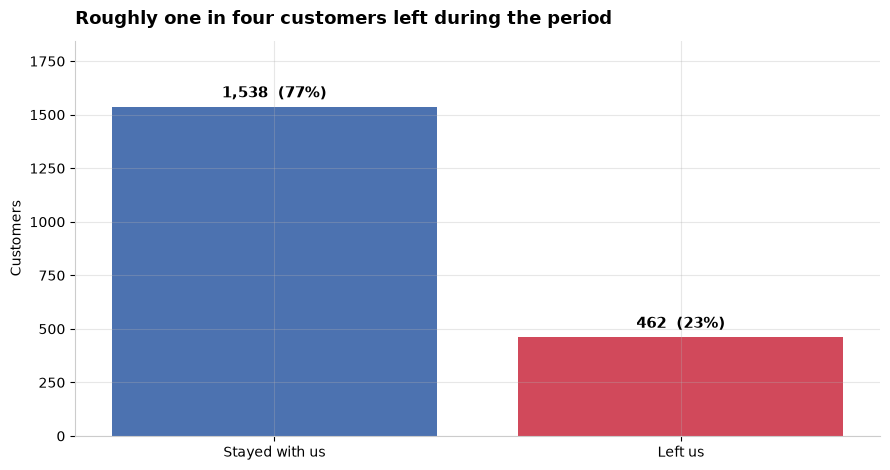

In [4]:
counts = customers["Churn"].value_counts()
fig, ax = plt.subplots()
bars = ax.bar(["Stayed with us", "Left us"], [counts["No"], counts["Yes"]], color=[BLUE, RED])
ax.bar_label(bars,
             labels=[f"{counts['No']:,}  ({counts['No'] / len(customers):.0%})",
                     f"{counts['Yes']:,}  ({counts['Yes'] / len(customers):.0%})"],
             fontsize=11, fontweight="bold", padding=4)
ax.set_ylabel("Customers")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Roughly one in four customers left during the period", **TITLE)
plt.tight_layout()
plt.show()

**What this means:** 462 of our 2,000 customers — 23%, about one in four — cancelled during the period. The average leaver was paying roughly $70 a month, so this one group represents about **$387,000 of yearly revenue** walking out of the door. Churn is not a nuisance; it is one of the largest lines on the page, and it deserves a funded programme rather than ad-hoc saves.

### 3.1 First suspect: the type of contract

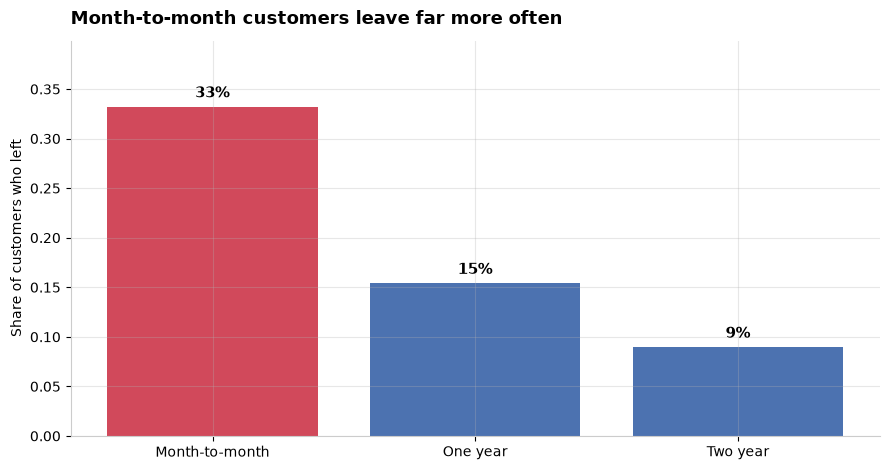

In [5]:
rate = customers["Churn"].eq("Yes").groupby(customers["Contract"]).mean()
rate = rate.reindex(["Month-to-month", "One year", "Two year"])
fig, ax = plt.subplots()
bars = ax.bar(rate.index, rate.values, color=[RED, BLUE, BLUE])
ax.bar_label(bars, fmt="{:.0%}", fontsize=11, fontweight="bold", padding=4)
ax.set_ylabel("Share of customers who left")
ax.set_ylim(0, rate.max() * 1.2)
ax.set_title("Month-to-month customers leave far more often", **TITLE)
plt.tight_layout()
plt.show()

**What this means:** customers on month-to-month contracts left at a rate of 33% — nearly four times the 9% rate of two-year customers, with one-year contracts in between at 15%. Commitment length is the single strongest pattern in the data. **Decision it supports:** offer a small discount to move month-to-month customers onto 12-month contracts; every customer who switches moves from the high-churn group into the low-churn group.

### 3.2 Second suspect: the internet service

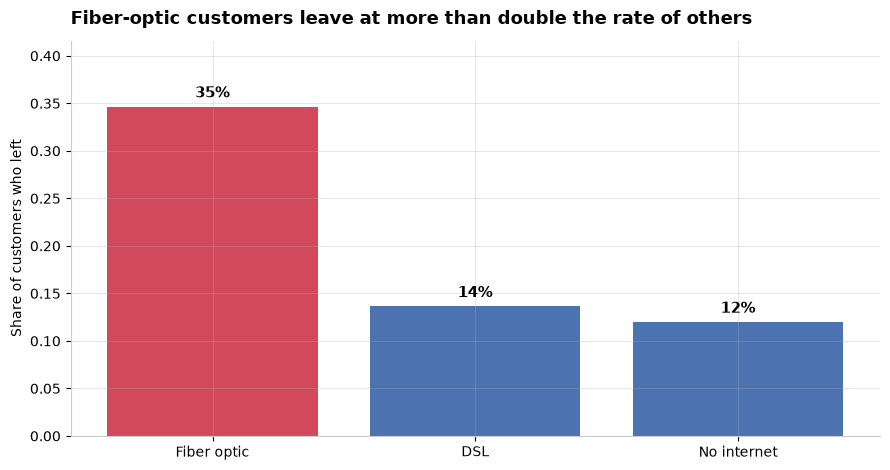

In [6]:
rate = customers["Churn"].eq("Yes").groupby(customers["Internet_Service"]).mean()
rate = rate.reindex(["Fiber optic", "DSL", "No internet"])
fig, ax = plt.subplots()
bars = ax.bar(rate.index, rate.values, color=[RED, BLUE, BLUE])
ax.bar_label(bars, fmt="{:.0%}", fontsize=11, fontweight="bold", padding=4)
ax.set_ylabel("Share of customers who left")
ax.set_ylim(0, rate.max() * 1.2)
ax.set_title("Fiber-optic customers leave at more than double the rate of others", **TITLE)
plt.tight_layout()
plt.show()

**What this means:** fiber-optic customers left at 35% — more than double the 14% of DSL customers and triple the 12% of customers with no internet service. Something about the fiber experience (its price, its reliability, or the expectations it sets) is pushing people out. **Decision it supports:** commission a quick service-quality and price-benchmark review of the fiber offer before we spend another dollar marketing it.

### 3.3 Third suspect: the add-on services

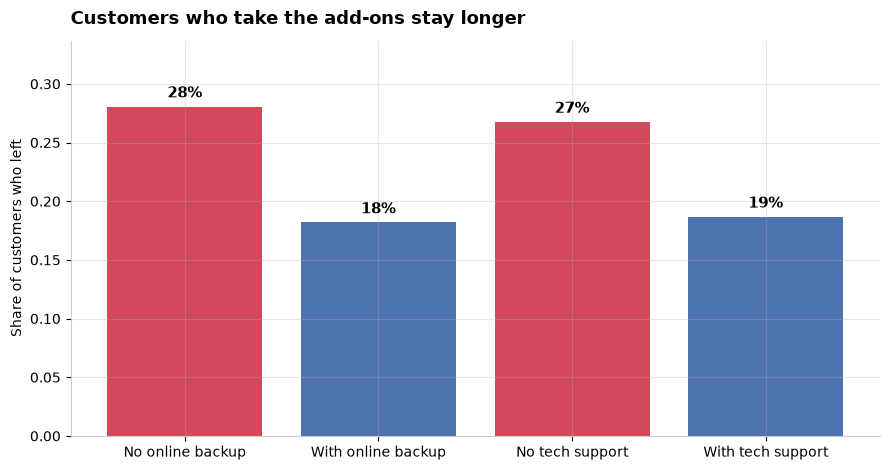

In [7]:
backup = customers["Churn"].eq("Yes").groupby(customers["Online_Backup"]).mean()
support = customers["Churn"].eq("Yes").groupby(customers["Tech_Support"]).mean()
labels = ["No online backup", "With online backup", "No tech support", "With tech support"]
values = [backup["No"], backup["Yes"], support["No"], support["Yes"]]
fig, ax = plt.subplots()
bars = ax.bar(labels, values, color=[RED, BLUE, RED, BLUE])
ax.bar_label(bars, fmt="{:.0%}", fontsize=11, fontweight="bold", padding=4)
ax.set_ylabel("Share of customers who left")
ax.set_ylim(0, max(values) * 1.2)
ax.set_title("Customers who take the add-ons stay longer", **TITLE)
plt.tight_layout()
plt.show()

**What this means:** customers without online backup left at 28% versus 18% with it; without tech support 27% versus 19% with it. The add-ons appear to *stick* customers to us — most likely because every extra service makes switching to a competitor more hassle. **Decision it supports:** enrol every new sign-up into backup and support by default (free for the first 90 days) instead of waiting for them to discover the add-ons themselves.

### 3.4 Fourth suspect: how new the customer is

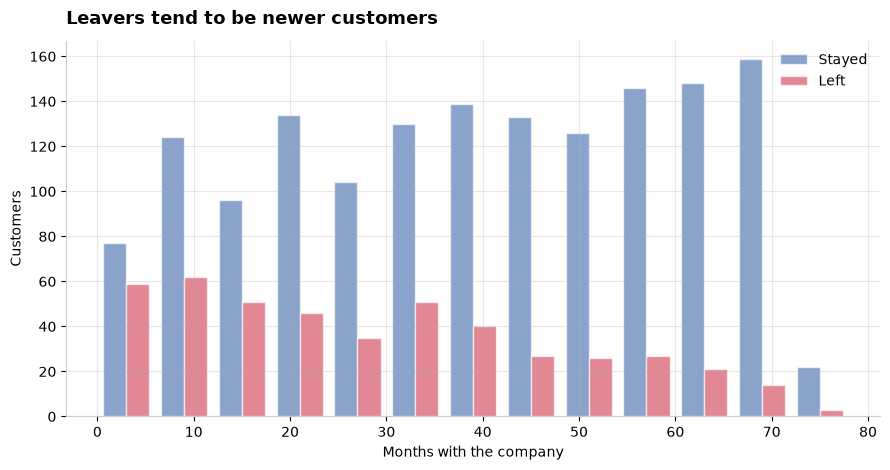

Median tenure of customers who left: 25 months
Median tenure of customers who stayed: 40 months


In [8]:
stayed = customers.loc[customers["Churn"] == "No", "Tenure_Months"]
left = customers.loc[customers["Churn"] == "Yes", "Tenure_Months"]
fig, ax = plt.subplots()
ax.hist([stayed, left], bins=range(0, 79, 6), color=[BLUE, RED], alpha=0.65,
        label=["Stayed", "Left"], edgecolor="white")
ax.legend(frameon=False)
ax.set_xlabel("Months with the company")
ax.set_ylabel("Customers")
ax.set_title("Leavers tend to be newer customers", **TITLE)
plt.tight_layout()
plt.show()
print(f"Median tenure of customers who left: {left.median():.0f} months")
print(f"Median tenure of customers who stayed: {stayed.median():.0f} months")

**What this means:** the typical leaver had been with us 25 months, versus 40 months for stayers, and 30% of leavers quit inside their first year compared with 14% of stayers. The first year is the danger zone. **Decision it supports:** add structured check-ins at day 30, day 90 and month 12 of every new customer's life, instead of waiting for a cancellation request to hear from them.

### 3.5 Fifth suspect: the size of the bill

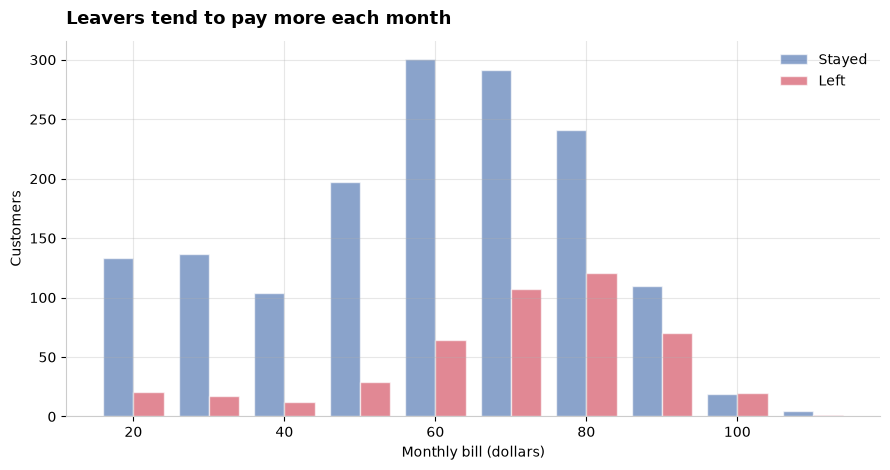

Average monthly bill of customers who left: $69.86
Average monthly bill of customers who stayed: $59.01


In [9]:
stayed_bill = customers.loc[customers["Churn"] == "No", "Monthly_Charges"]
left_bill = customers.loc[customers["Churn"] == "Yes", "Monthly_Charges"]
fig, ax = plt.subplots()
ax.hist([stayed_bill, left_bill], bins=range(15, 125, 10), color=[BLUE, RED], alpha=0.65,
        label=["Stayed", "Left"], edgecolor="white")
ax.legend(frameon=False)
ax.set_xlabel("Monthly bill (dollars)")
ax.set_ylabel("Customers")
ax.set_title("Leavers tend to pay more each month", **TITLE)
plt.tight_layout()
plt.show()
print(f"Average monthly bill of customers who left: ${left_bill.mean():.2f}")
print(f"Average monthly bill of customers who stayed: ${stayed_bill.mean():.2f}")

**What this means:** leavers paid about $70 a month on average, against about $59 for stayers. Part of this gap is simply fiber being pricier, but the difference is large enough to deserve attention. **Decision it supports:** review whether our highest bills deliver visible value — particularly around months 6 to 12, where sticker shock meets renewal.

## 4. Building a simple early-warning tool

The graphs above describe the past. Management needs the future: *which of today's customers will leave next?* To answer that we build a scoring tool — in data-science language a **logistic regression**, chosen deliberately because it is transparent: it gives every customer one risk score, and we can explain exactly which facts pushed that score up or down.

To prove the tool works honestly, we let it learn from only 1,500 of the 2,000 customers ("training") and hide the remaining 500 completely ("the test set"). Every result below is measured on those 500 customers the tool has never seen — the closest we can get to watching it work on tomorrow's customers.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

target = (customers["Churn"] == "Yes").astype(int)
features = pd.get_dummies(customers.drop(columns=["CustomerID", "Churn"]),
                          columns=["Contract", "Internet_Service", "Online_Backup", "Tech_Support"]).astype(int)
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.25,
                                                    stratify=target, random_state=42)
model = LogisticRegression(max_iter=2000).fit(X_train, y_train)

test_customers = customers.iloc[X_test.index].copy()
test_customers["RiskScore"] = model.predict_proba(X_test)[:, 1]
print(f"Trained on {len(X_train):,} customers; held back {len(X_test):,} unseen customers for testing.")
print(f"Separation score (AUC): {roc_auc_score(y_test, test_customers['RiskScore']):.2f}   (0.50 = coin flip, 1.00 = perfect)")

Trained on 1,500 customers; held back 500 unseen customers for testing.
Separation score (AUC): 0.78   (0.50 = coin flip, 1.00 = perfect)


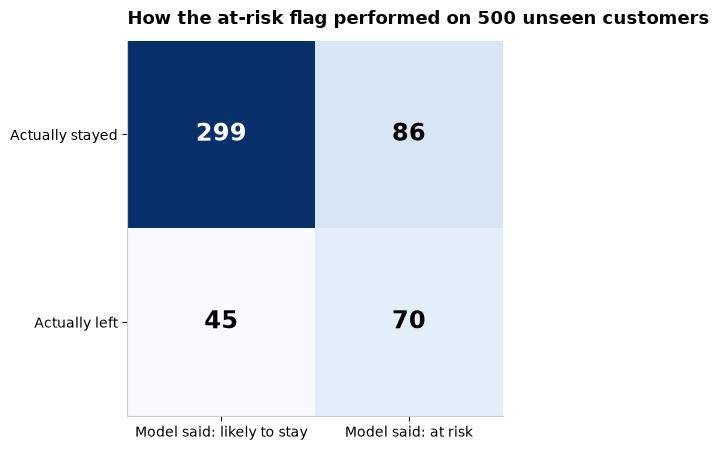

Flagged as at-risk: 156 of 500 customers
Of those flagged, 45% actually left (company average: 23%)
The flag caught 61% of all customers who ended up leaving


In [11]:
from sklearn.metrics import confusion_matrix

FLAG_THRESHOLD = 0.30
flagged = test_customers["RiskScore"] >= FLAG_THRESHOLD
actual_left = test_customers["Churn"] == "Yes"
tn, fp, fn, tp = confusion_matrix(actual_left, flagged).ravel()
matrix = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.imshow(matrix, cmap="Blues")
ax.set_xticks([0, 1], ["Model said: likely to stay", "Model said: at risk"])
ax.set_yticks([0, 1], ["Actually stayed", "Actually left"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center",
                fontsize=17, fontweight="bold",
                color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ax.grid(False)
ax.set_title("How the at-risk flag performed on 500 unseen customers", **TITLE)
plt.tight_layout()
plt.show()

print(f"Flagged as at-risk: {int(flagged.sum())} of {len(test_customers)} customers")
print(f"Of those flagged, {tp / (tp + fp):.0%} actually left (company average: {actual_left.mean():.0%})")
print(f"The flag caught {tp / (tp + fn):.0%} of all customers who ended up leaving")

**What this means:** we told the tool to flag anyone scoring 30% risk or higher. On the 500 unseen customers it flagged 156 people — and 70 of them (45%) really did leave, about double the 23% company average. Just as important, the flag caught **61% of everyone who left**: for every ten future leavers we now get six names in advance instead of zero. The 86 flagged customers who stayed are not "errors": they were genuinely high-risk, and a retention offer sent to them is money spent on the right people. *(Technical footnote for the curious: the score separates leavers from stayers with an AUC of 0.78 — pick one leaver and one stayer at random, and the score ranks the leaver higher 78% of the time.)*

### 4.1 Proof that the score ranks customers correctly

A good score does not only flag — it *orders*. Below, the 500 test customers are split into five equal groups, from lowest score to highest, and we show how many in each group actually left.

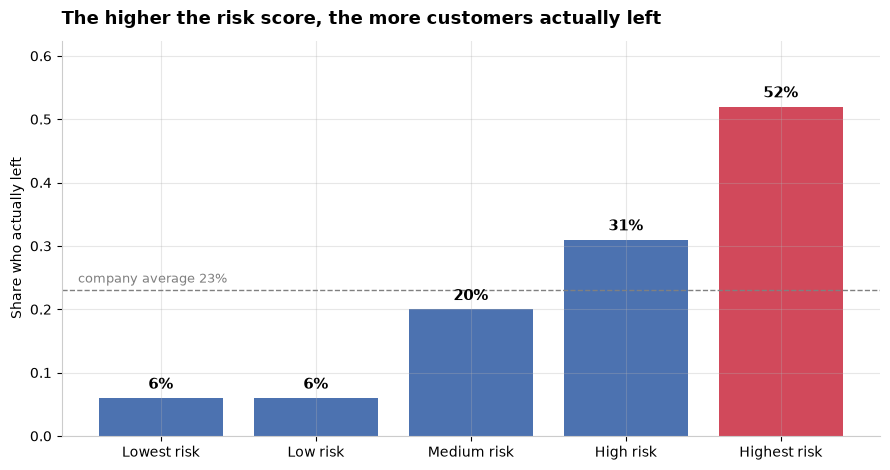

In [12]:
bands = pd.qcut(test_customers["RiskScore"], 5,
                labels=["Lowest risk", "Low risk", "Medium risk", "High risk", "Highest risk"])
band_rate = actual_left.groupby(bands, observed=True).mean()
fig, ax = plt.subplots()
bars = ax.bar(band_rate.index.astype(str), band_rate.values, color=[BLUE, BLUE, BLUE, BLUE, RED])
ax.bar_label(bars, fmt="{:.0%}", fontsize=11, fontweight="bold", padding=4)
ax.axhline(actual_left.mean(), ls="--", lw=1, color="gray")
ax.text(0.02, actual_left.mean() + 0.012, f"company average {actual_left.mean():.0%}",
        transform=ax.get_yaxis_transform(), ha="left", color="gray", fontsize=9)
ax.set_ylabel("Share who actually left")
ax.set_ylim(0, band_rate.max() * 1.2)
ax.set_title("The higher the risk score, the more customers actually left", **TITLE)
plt.tight_layout()
plt.show()

**What this means:** the ladder is almost perfectly ordered: 6% of the lowest-risk group left, then 6%, 20%, 31%, and finally **52% of the highest-risk group**. When the tool says "high risk", it means it. **Decision it supports:** use the score as the retention team's priority order — work the call list top-down, always starting from the highest scores.

### 4.2 What actually drives customers out

Because we chose a transparent model, we can read each fact's contribution directly. The graph shows how much each fact multiplies the *odds* of leaving, holding everything else equal. A bar to the right of the dashed line pushes customers out of the door; a bar to the left keeps them with us.

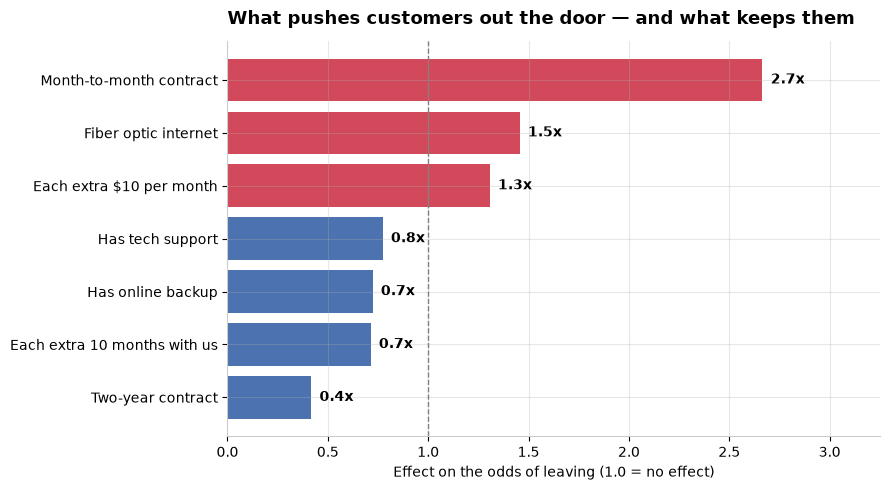

In [13]:
coef = pd.Series(model.coef_[0], index=features.columns)
drivers = pd.Series({
    "Month-to-month contract": np.exp(coef["Contract_Month-to-month"]),
    "Fiber optic internet": np.exp(coef["Internet_Service_Fiber optic"]),
    "Each extra $10 per month": np.exp(10 * coef["Monthly_Charges"]),
    "Has tech support": np.exp(coef["Tech_Support_Yes"]),
    "Has online backup": np.exp(coef["Online_Backup_Yes"]),
    "Each extra 10 months with us": np.exp(10 * coef["Tenure_Months"]),
    "Two-year contract": np.exp(coef["Contract_Two year"]),
}).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(drivers.index, drivers.values, color=[RED if v > 1 else BLUE for v in drivers.values])
ax.axvline(1.0, ls="--", lw=1, color="gray")
ax.bar_label(bars, fmt="%.1fx", padding=6, fontsize=10, fontweight="bold")
ax.set_xlim(0, drivers.max() * 1.22)
ax.set_xlabel("Effect on the odds of leaving (1.0 = no effect)")
ax.set_title("What pushes customers out the door — and what keeps them", **TITLE)
plt.tight_layout()
plt.show()

**What this means:** the biggest push factor is a **month-to-month contract (2.7x the odds of leaving)**, followed by fiber internet (1.5x) and a high bill (1.3x per extra $10). The biggest keep factors are a **two-year contract (0.4x, i.e. 60% lower odds)**, longer tenure (0.7x per extra ten months) and the two add-ons (0.7–0.8x). These mirror Section 3 exactly, which is reassuring: the model is not discovering magic, it is quantifying patterns a manager can act on. **Decision it supports:** the recommendations in Section 6, in priority order.

## 5. Putting the tool to work today

The 500 test customers now play the role of *today's active book*: people the model scored but whose fate it never learned from. Below is the top of the at-risk call list it produces; the complete list is saved to **`at_risk_customers.csv`** next to this notebook, ready to hand to the retention team as it is.

In [14]:
call_list = test_customers.loc[flagged].sort_values("RiskScore", ascending=False)

view = call_list[["CustomerID", "Contract", "Internet_Service", "Tenure_Months", "Monthly_Charges", "RiskScore"]].head(10).copy()
view["RiskScore"] = (view["RiskScore"] * 100).round(0).astype(int).astype(str) + "%"
view.columns = ["Customer", "Contract", "Internet", "Months with us", "Monthly bill", "Risk of leaving"]
display(view)

export = call_list[["CustomerID", "Contract", "Internet_Service", "Tenure_Months", "Monthly_Charges", "RiskScore"]].copy()
export["RiskScore"] = (export["RiskScore"] * 100).round(1)
export.columns = ["CustomerID", "Contract", "InternetService", "TenureMonths", "MonthlyCharges", "RiskPercent"]
export.to_csv("at_risk_customers.csv", index=False)
print(f"Full call list of {len(call_list)} at-risk customers saved to at_risk_customers.csv")

,Customer,Contract,Internet,Months with us,Monthly bill,Risk of leaving
1462,C-1463,Month-to-month,Fiber optic,4,96.49,89%
1165,C-1166,Month-to-month,Fiber optic,8,95.34,87%
1629,C-1630,Month-to-month,Fiber optic,10,95.95,86%
195,C-0196,Month-to-month,Fiber optic,7,90.84,86%
1350,C-1351,Month-to-month,Fiber optic,5,87.38,86%
974,C-0975,Month-to-month,Fiber optic,11,87.25,83%
673,C-0674,Month-to-month,Fiber optic,7,95.40,80%
749,C-0750,Month-to-month,Fiber optic,12,82.04,80%
116,C-0117,Month-to-month,Fiber optic,3,87.99,79%
857,C-0858,Month-to-month,Fiber optic,5,87.55,78%


Full call list of 156 at-risk customers saved to at_risk_customers.csv


**What this means:** each row is one customer to call this week, with the facts a retention agent needs on the screen: contract, service, tenure, bill and risk. The list is ordered so that the first call is the most valuable call. **Decision it supports:** make working this list a standing weekly routine, not a one-off campaign.

In [15]:
offer_cost = 60.0
assumed_save_rate = 0.30
annual_value_per_lost_customer = customers.loc[customers["Churn"] == "Yes", "Monthly_Charges"].mean() * 12

expected_leavers = call_list["RiskScore"].sum()
program_cost = offer_cost * len(call_list)
revenue_protected = expected_leavers * assumed_save_rate * annual_value_per_lost_customer
break_even_save_rate = program_cost / (expected_leavers * annual_value_per_lost_customer)

print(f"Contacting all {len(call_list)} flagged customers with a ${offer_cost:.0f} save-offer costs ${program_cost:,.0f}.")
print(f"The model expects about {expected_leavers:.0f} of them to leave.")
print(f"If the offer convinces 30% of those to stay ({expected_leavers * assumed_save_rate:.0f} customers),")
print(f"we protect ${revenue_protected:,.0f} of yearly revenue (each lost customer is worth ${annual_value_per_lost_customer:,.0f}/year).")
print(f"Net benefit: ${revenue_protected - program_cost:,.0f}")
print(f"The programme pays for itself if it saves more than {break_even_save_rate:.0%} of the flagged leavers.")

Contacting all 156 flagged customers with a $60 save-offer costs $9,360.
The model expects about 77 of them to leave.
If the offer convinces 30% of those to stay (23 customers),
we protect $19,291 of yearly revenue (each lost customer is worth $838/year).
Net benefit: $9,931
The programme pays for itself if it saves more than 15% of the flagged leavers.


**What this means:** contacting all 156 flagged customers with a $60 save-offer costs about **$9,400**. The model expects roughly 77 of them to leave; if the offer persuades even 30% of those to stay (23 customers), we protect about **$19,300 of yearly revenue** — a net gain of roughly **$9,900** from a single quarter's list of just 500 customers. The programme breaks even even if it saves only 15% of the flagged leavers (about one in seven). **Decision it supports:** approve the save-offer budget; the downside is small and the upside scales with the full customer book.

## 6. Recommendations — the decisions we suggest

1. **Move month-to-month customers onto 12-month contracts.** The strongest lever in the data (2.7x the odds of leaving). Offer a modest monthly discount for switching; even converting a third of month-to-month customers shifts hundreds of them from the 33% churn group into the 15% group.
2. **Fix or reprice the fiber-optic experience.** Fiber churn (35%) is more than double DSL (14%). Run a service-quality and price-benchmark review before the next fiber marketing push.
3. **Make online backup and tech support the default at sign-up.** Free for 90 days, then opt-out rather than opt-in. Both add-ons are associated with roughly 10 percentage points less churn.
4. **Work the model's call list every week with a $60 save-offer.** Return computed above: about $9,900 net per quarter per 500 customers, breaking even at a 15% save rate.
5. **Add first-year onboarding check-ins (day 30 / day 90 / month 12).** Leavers skew new — median 25 months with us, 30% gone inside year one — and early contact is the cheapest save there is.

## 7. Limitations — please read before quoting any number

- The analysis runs on the 2,000-customer extract shipped with this notebook (`customer_data.csv`). When a fresh billing export arrives, re-run the notebook top to bottom: every graph, score and dollar figure updates automatically.
- The drivers above are **associations, not proven causes**. Before rolling any recommendation out company-wide, pilot it on a random half of the target group and compare (an A/B test).
- The tool catches 61% of leavers, not all of them. It is a priority list, not a crystal ball; universally good service remains the baseline retention programme.
- Retrain the model quarterly — as the customer mix shifts, yesterday's weights go stale.
- Use the score to decide whom to **help**, never to penalise customers or to target staff.

## 8. Bottom line

One in four customers left during the period — about $387,000 of yearly revenue. Who leaves is not random: it concentrates in month-to-month contracts, fiber customers, high bills and the first year of tenure. A simple, explainable score now ranks every customer by risk (the highest-risk group left at 52% versus 6% for the lowest), and a $60-offer programme on the flagged list pays for itself several times over. The five decisions in Section 6 turn churn from a quarterly surprise into a weekly work queue with a measured return.